<a href="https://colab.research.google.com/github/shakirullah-khan/snow-cover-segmentation-deep-learning/blob/main/notebooks/cnn_baseline_models/03_SegNet_VGG16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


This notebook contains the complete training log and evaluation output for SegNet_VGG16 on 9,026 Sentinel-2 patches. The run was executed using Google Colab GPU resources. Cell outputs below reflect the completed experiment.

In [ ]:
# Install dependencies
!pip install -q webdataset albumentations

# Imports
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
import webdataset as wds
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import random
import warnings
warnings.filterwarnings("ignore")

print("✅ SegNet VGG16 Environment Ready!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ SegNet VGG16 Environment Ready!


In [ ]:
drive_dataset_path = "/content/drive/My Drive/Swat_Snow_Cover_Project/WebDataset/snow_patches_5000_random.tar"
colab_dataset_path = "/tmp/snow_patches_5000_random.tar"

os.makedirs(os.path.dirname(colab_dataset_path), exist_ok=True)
print("📥 Copying dataset...")
shutil.copy(drive_dataset_path, colab_dataset_path)
print(f"✅ Dataset: {os.path.getsize(colab_dataset_path)/1024**3:.2f} GB")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Device: {device}")
wds_path = colab_dataset_path

📥 Copying dataset...
✅ Dataset: 0.41 GB
🚀 Device: cuda


In [ ]:
MODEL_NAME = "SegNet_VGG16"
final_results_path = "/content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results"
model_results_path = os.path.join(final_results_path, MODEL_NAME)

os.makedirs(model_results_path, exist_ok=True)
print(f"📁 Results Path: {model_results_path}")

📁 Results Path: /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/SegNet_VGG16


In [ ]:
CONFIG = {
    "model_name": MODEL_NAME,
    "encoder_name": "vgg16",
    "num_epochs": 50,
    "batch_size": 16,
    "learning_rate": 1e-4,
    "num_workers": 0,
    "total_patches": 5000
}

CONFIG["train_size"] = int(CONFIG["total_patches"] * 0.7)
CONFIG["val_size"] = int(CONFIG["total_patches"] * 0.2)
CONFIG["test_size"] = CONFIG["total_patches"] - CONFIG["train_size"] - CONFIG["val_size"]

train_batches = CONFIG["train_size"] // CONFIG["batch_size"]
val_batches = CONFIG["val_size"] // CONFIG["batch_size"]

print(f"📊 Train/Val/Test Split: {CONFIG['train_size']}/{CONFIG['val_size']}/{CONFIG['test_size']}")

📊 Train/Val/Test Split: 3500/1000/500


In [ ]:
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.2, rotate_limit=30, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

def preprocess_sample(sample, transform):
    img = np.array(sample["image.png"].convert("RGB"))
    msk = np.array(sample["mask.png"].convert("L")) / 255.0
    t = transform(image=img, mask=msk)
    return t["image"], t["mask"].unsqueeze(0)

In [ ]:
train_dataset = (wds.WebDataset(wds_path)
    .shuffle(1000).decode("pil").to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, train_transform))
    .batched(CONFIG["batch_size"]))

val_dataset = (wds.WebDataset(wds_path)
    .decode("pil").to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, val_transform))
    .batched(CONFIG["batch_size"]))

train_loader = wds.WebLoader(train_dataset, batch_size=None, num_workers=CONFIG["num_workers"]).with_epoch(train_batches)
val_loader = wds.WebLoader(val_dataset, batch_size=None, num_workers=CONFIG["num_workers"]).with_epoch(val_batches)

print("✅ Data loaders ready!")

✅ Data loaders ready!


In [ ]:
class SegNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(SegNet, self).__init__()

        # FIXED: Use .DEFAULT or .IMAGENET1K_V1
        vgg16 = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
        features = list(vgg16.features.children())

        # Encoder stages
        self.enc1 = nn.Sequential(*features[0:4])   # 64
        self.enc2 = nn.Sequential(*features[5:9])   # 128
        self.enc3 = nn.Sequential(*features[10:16]) # 256
        self.enc4 = nn.Sequential(*features[17:23]) # 512
        self.enc5 = nn.Sequential(*features[24:30]) # 512

        self.pool = nn.MaxPool2d(2, stride=2, return_indices=True)
        self.unpool = nn.MaxUnpool2d(2, stride=2)

        # Decoder stages
        self.dec5 = self._make_dec_block(512, 512, 3)
        self.dec4 = self._make_dec_block(512, 256, 3)
        self.dec3 = self._make_dec_block(256, 128, 3)
        self.dec2 = self._make_dec_block(128, 64, 2)
        self.dec1 = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, out_channels, kernel_size=3, padding=1)
        )

    def _make_dec_block(self, in_f, out_f, num_convs):
        layers = []
        for i in range(num_convs):
            layers.append(nn.Conv2d(in_f if i == 0 else out_f, out_f, kernel_size=3, padding=1))
            layers.append(nn.BatchNorm2d(out_f))
            layers.append(nn.ReLU(inplace=True))
        return nn.Sequential(*layers)

    def forward(self, x):
        # Encoder
        # IMPORTANT: SegNet uses the indices (id) from pooling to unpool in the decoder
        e1, id1 = self.pool(self.enc1(x))
        e2, id2 = self.pool(self.enc2(e1))
        e3, id3 = self.pool(self.enc3(e2))
        e4, id4 = self.pool(self.enc4(e3))
        e5, id5 = self.pool(self.enc5(e4))

        # Decoder
        d5 = self.dec5(self.unpool(e5, id5))
        d4 = self.dec4(self.unpool(d5, id4))
        d3 = self.dec3(self.unpool(d4, id3))
        d2 = self.dec2(self.unpool(d3, id2))
        d1 = self.dec1(self.unpool(d2, id1))
        return d1

model = SegNet(in_channels=3, out_channels=1).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"✅ SegNet VGG16 Built! Parameters: {total_params:,}")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 87.1MB/s]


✅ SegNet VGG16 Built! Parameters: 24,898,369


In [ ]:
class DiceBCELoss(nn.Module):
    def __init__(self): super().__init__(); self.bce = nn.BCEWithLogitsLoss()
    def forward(self, pred, target):
        bce = self.bce(pred, target)
        p = torch.sigmoid(pred)
        inter = (p * target).sum()
        dice = 1 - (2 * inter + 1e-6) / (p.sum() + target.sum() + 1e-6)
        return 0.5 * bce + 0.5 * dice

def calc_iou(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    inter = (pred * target).sum()
    union = pred.sum() + target.sum() - inter
    return (inter + 1e-6) / (union + 1e-6)

def calc_dice(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    inter = (pred * target).sum()
    return (2 * inter + 1e-6) / (pred.sum() + target.sum() + 1e-6)

def calc_precision(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    tp = (pred * target).sum()
    return (tp + 1e-6) / (pred.sum() + 1e-6)

def calc_recall(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    tp = (pred * target).sum()
    return (tp + 1e-6) / (target.sum() + 1e-6)

criterion = DiceBCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=5, factor=0.5)

history = {"train_loss":[], "val_loss":[], "train_iou":[], "val_iou":[],
           "train_dice":[], "val_dice":[], "train_precision":[], "val_precision":[],
           "train_recall":[], "val_recall":[], "learning_rate":[]}

best_dice = 0.0

In [ ]:
def train_epoch(model, loader, num_batches):
    model.train()
    metrics = {k: [] for k in ["loss", "iou", "dice", "precision", "recall"]}
    pbar = tqdm(enumerate(loader), total=num_batches, desc="Train")
    for bi, (imgs, msks) in pbar:
        if bi >= num_batches: break
        imgs, msks = imgs.to(device), msks.to(device)
        optimizer.zero_grad()
        preds = model(imgs)
        loss = criterion(preds, msks)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        metrics["loss"].append(loss.item())
        metrics["iou"].append(calc_iou(preds, msks).item())
        metrics["dice"].append(calc_dice(preds, msks).item())
        metrics["precision"].append(calc_precision(preds, msks).item())
        metrics["recall"].append(calc_recall(preds, msks).item())
        pbar.set_postfix(loss=f"{np.mean(metrics['loss']):.4f}", dice=f"{np.mean(metrics['dice']):.4f}")
    return {k: np.mean(v) for k, v in metrics.items()}

def val_epoch(model, loader, num_batches):
    model.eval()
    metrics = {k: [] for k in ["loss", "iou", "dice", "precision", "recall"]}
    with torch.no_grad():
        pbar = tqdm(enumerate(loader), total=num_batches, desc="Val")
        for bi, (imgs, msks) in pbar:
            if bi >= num_batches: break
            imgs, msks = imgs.to(device), msks.to(device)
            preds = model(imgs)
            loss = criterion(preds, msks)
            metrics["loss"].append(loss.item())
            metrics["iou"].append(calc_iou(preds, msks).item())
            metrics["dice"].append(calc_dice(preds, msks).item())
            metrics["precision"].append(calc_precision(preds, msks).item())
            metrics["recall"].append(calc_recall(preds, msks).item())
            pbar.set_postfix(loss=f"{np.mean(metrics['loss']):.4f}", dice=f"{np.mean(metrics['dice']):.4f}")
    return {k: np.mean(v) for k, v in metrics.items()}

In [ ]:
print("="*80)
print(f"🚀 {MODEL_NAME} TRAINING START")
print("="*80)

for epoch in range(CONFIG["num_epochs"]):
    print(f"\nEpoch {epoch+1}/{CONFIG['num_epochs']}")
    train_m = train_epoch(model, train_loader, train_batches)
    val_m = val_epoch(model, val_loader, val_batches)

    scheduler.step(val_m["loss"])
    lr = optimizer.param_groups[0]["lr"]

    for k in train_m.keys():
        history[f"train_{k}"].append(train_m[k])
        history[f"val_{k}"].append(val_m[k])
    history["learning_rate"].append(lr)

    if val_m["dice"] > best_dice:
        best_dice = val_m["dice"]
        torch.save(model.state_dict(), os.path.join(model_results_path, "best_model.pth"))
        print(f"  ⭐ NEW BEST: {best_dice:.4f}")

🚀 SegNet_VGG16 TRAINING START

Epoch 1/50


Val: 100%|██████████| 62/62 [00:15<00:00,  4.03it/s, dice=0.8643, loss=0.2310]


  ⭐ NEW BEST: 0.8643

Epoch 2/50


Val: 100%|██████████| 62/62 [00:15<00:00,  4.00it/s, dice=0.9015, loss=0.1653]


  ⭐ NEW BEST: 0.9015

Epoch 3/50


Val: 100%|██████████| 62/62 [00:15<00:00,  3.95it/s, dice=0.9109, loss=0.1362]


... (90 outputs left out)


Epoch 49/50


Val: 100%|██████████| 62/62 [00:16<00:00,  3.81it/s, dice=0.9468, loss=0.0781]


  ⭐ NEW BEST: 0.9468

Epoch 50/50


Val: 100%|██████████| 62/62 [00:15<00:00,  3.90it/s, dice=0.9466, loss=0.0784]


In [ ]:
torch.save(model.state_dict(), os.path.join(model_results_path, "final_model.pth"))
pd.DataFrame(history).to_csv(os.path.join(model_results_path, "training_history.csv"), index=False)
print(f"✅ Results saved to {model_results_path}")

✅ Results saved to /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/SegNet_VGG16


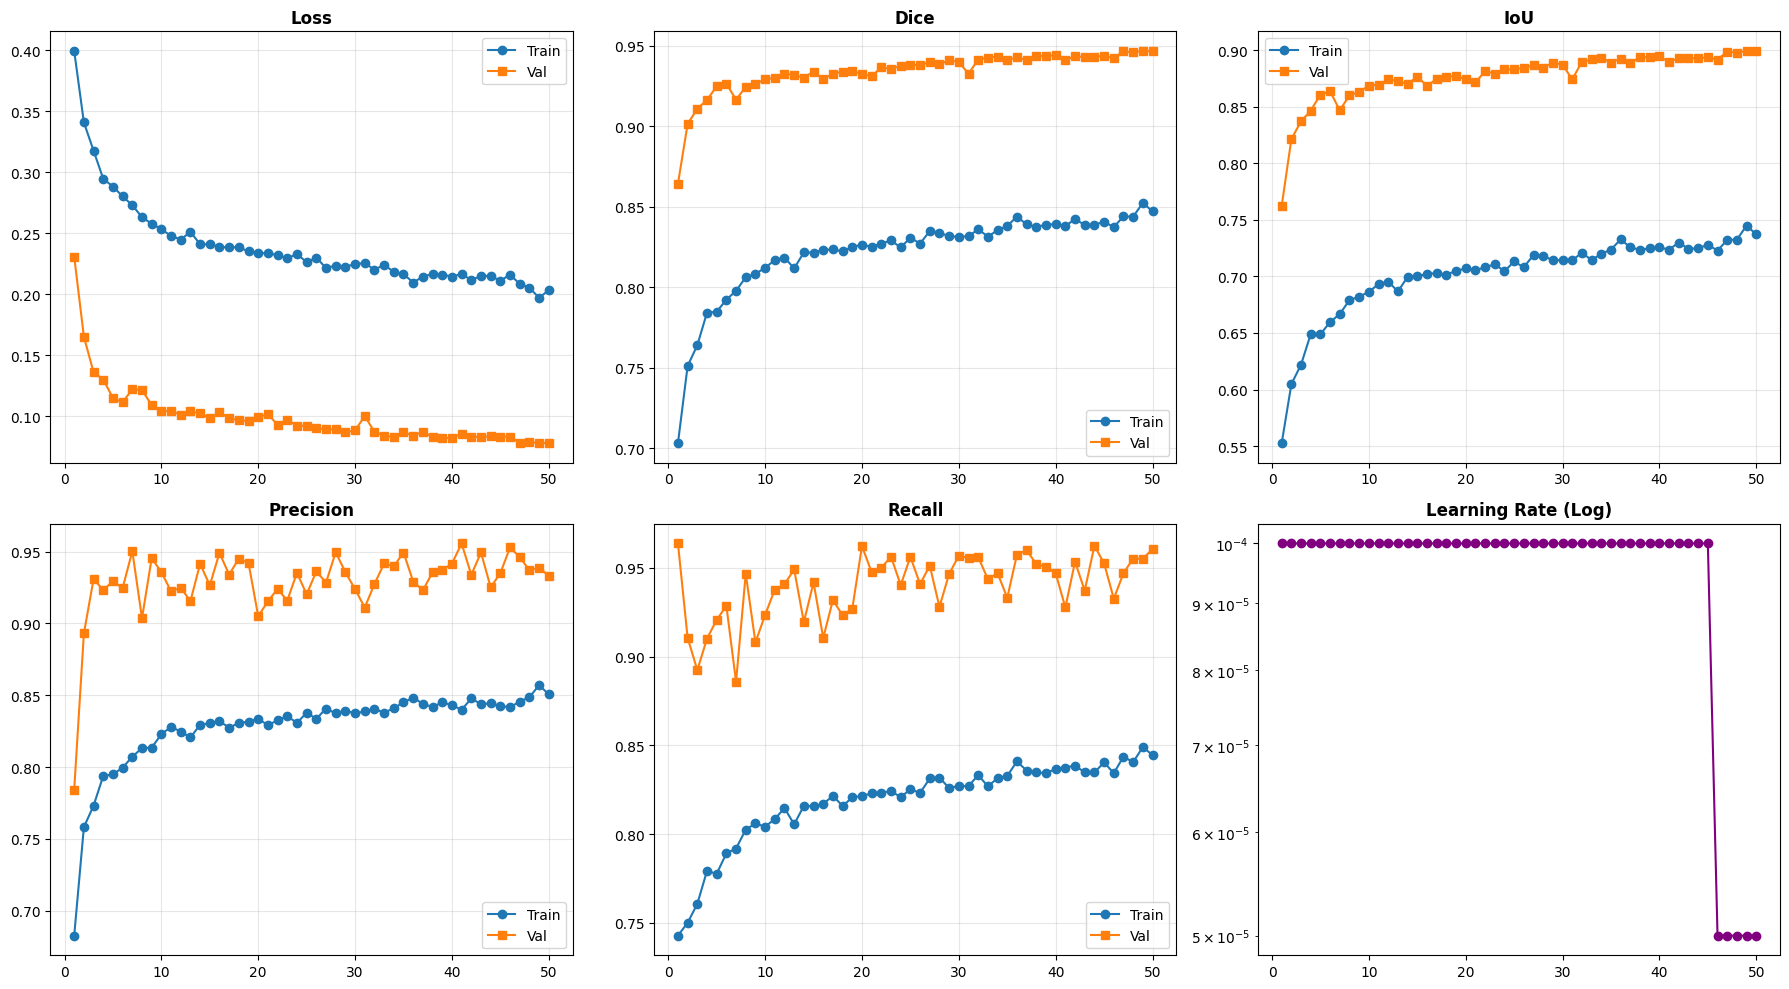

In [ ]:
epochs_range = np.arange(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
metrics_to_plot = [("loss", "Loss"), ("dice", "Dice"), ("iou", "IoU"), ("precision", "Precision"), ("recall", "Recall")]

for i, (m, title) in enumerate(metrics_to_plot):
    row, col = divmod(i, 3)
    axes[row, col].plot(epochs_range, history[f"train_{m}"], "o-", label="Train")
    axes[row, col].plot(epochs_range, history[f"val_{m}"], "s-", label="Val")
    axes[row, col].set_title(title, fontweight="bold")
    axes[row, col].legend(); axes[row, col].grid(alpha=0.3)

axes[1, 2].plot(epochs_range, history["learning_rate"], "o-", color="purple")
axes[1, 2].set_title("Learning Rate (Log)", fontweight="bold"); axes[1, 2].set_yscale("log")

plt.tight_layout()
plt.savefig(os.path.join(model_results_path, "training_curves.png"), dpi=300)
plt.show()

In [ ]:
import matplotlib.patches as mpatches

print("\n🎨 TEST PREDICTIONS VISUALIZATION")
print("="*50)

# 1. Load the best model weights
best_model_path = os.path.join(model_results_path, "best_model.pth")
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()

# 2. Get Test Samples (Indices after Train/Val)
raw_ds = wds.WebDataset(wds_path).decode("pil").to_tuple("image.png", "mask.png")
all_samples = list(raw_ds)
random.seed(42)
num_samples = 8
test_indices = random.sample(range(CONFIG["train_size"] + CONFIG["val_size"], len(all_samples)), num_samples)

# 3. Generate Predictions
fig, axes = plt.subplots(num_samples, 4, figsize=(20, 4*num_samples))

with torch.no_grad():
    for i, idx in enumerate(test_indices):
        img_pil, mask_pil = all_samples[idx]
        img_np = np.array(img_pil.convert("RGB"))
        mask_np = (np.array(mask_pil.convert("L")) / 255.0).astype(np.float32)

        # Preprocess for model
        t = val_transform(image=img_np, mask=mask_np)
        img_t = t["image"].unsqueeze(0).to(device)

        # Forward pass
        pred = model(img_t)
        pred_prob = torch.sigmoid(pred).squeeze().cpu().numpy()
        pred_bin = (pred_prob > 0.5).astype(np.uint8)

        # Calculate scores for this specific sample
        d = calc_dice(torch.from_numpy(pred_prob).unsqueeze(0).unsqueeze(0),
                      torch.from_numpy(mask_np).unsqueeze(0).unsqueeze(0)).item()
        j = calc_iou(torch.from_numpy(pred_prob).unsqueeze(0).unsqueeze(0),
                     torch.from_numpy(mask_np).unsqueeze(0).unsqueeze(0)).item()

        # Create Overlays (White = Snow)
        pred_overlay = img_np.copy().astype(np.uint8)
        pred_overlay[pred_bin == 1] = 255

        gt_overlay = img_np.copy().astype(np.uint8)
        gt_overlay[mask_np > 0.5] = 255

        # Plotting
        # Col 1: Original Image
        axes[i, 0].imshow(img_np.astype(np.uint8))
        axes[i, 0].set_title(f"Original\n#{idx}", fontweight="bold")
        axes[i, 0].axis("off")

        # Col 2: Ground Truth
        axes[i, 1].imshow(gt_overlay)
        axes[i, 1].set_title("Ground Truth\n(White=Snow)", fontweight="bold")
        axes[i, 1].axis("off")

        # Col 3: Probability Heatmap
        im = axes[i, 2].imshow(pred_prob, cmap="plasma", vmin=0, vmax=1)
        axes[i, 2].set_title(f"Probability\nDice={d:.3f}", fontweight="bold")
        axes[i, 2].axis("off")
        plt.colorbar(im, ax=axes[i, 2], fraction=0.046, pad=0.04)

        # Col 4: Predicted Snow
        axes[i, 3].imshow(pred_overlay)
        axes[i, 3].set_title("Predicted Snow\n(White=Snow)", fontweight="bold")
        axes[i, 3].axis("off")

# Add legend and save
legend_elements = [mpatches.Patch(color='white', label='Detected Snow')]
fig.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(0.95, 0.98))

plt.suptitle(f"{MODEL_NAME} - Test Visualizations (Best Val Dice: {best_dice:.4f})",
             fontsize=20, fontweight="bold", y=1.0)
plt.tight_layout()

vis_path = os.path.join(model_results_path, "test_predictions_white_snow.png")
plt.savefig(vis_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ Visualization saved: {vis_path}")